# AI use statement
Generative AI (Claude) was used to help debug, refine and structure the Python code in this notebook, and to draft the plain-language descriptions of diagnoses and organisms used during exploratory analysis. Generative AI was not used to conceive the project or to choose its aims. All modelling decisions, analyses and interpretations are the author's own work, and the author takes full responsibility for this code.

IMPORT LIBRARIES (SETTING UP THE WORKBENCH)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from pathlib import Path
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 3)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

import sys, matplotlib, scipy, plotly
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__} | "
      f"seaborn {sns.__version__} | scipy {scipy.__version__} | plotly {plotly.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.18.1 | plotly 7.1.0


LOAD DATASET

In [2]:
DATA_DIR = Path("../data/synthetic_hospital")   # see data/README.md

patients = pd.read_csv(DATA_DIR/"patients.csv")
admissions = pd.read_csv(DATA_DIR/"admissions.csv")
ward = pd.read_csv(DATA_DIR/"ward_movements.csv")
medications = pd.read_csv(DATA_DIR/"medications.csv")
infection = pd.read_csv(DATA_DIR/"infection_events.csv")
device = pd.read_csv(DATA_DIR/"device_exposure.csv")

DATASET OVERVIEW

In [3]:
datasets = {
    "Patients": patients,
    "Admissions": admissions,
    "Ward": ward,
    "Medications": medications,
    "Infection": infection,
    "Device": device
}

# First rows of each table
for name, df in datasets.items():
    print("=" * 60)
    print(f"{name}: {len(df):,} rows")
    display(df.head())

Patients: 12,000 rows


,patient_id,sex,dob,age,postcode
0,1,Male,1944-12-23,78,4759
1,2,Male,1974-05-08,48,4228
2,3,Male,1950-01-14,73,4692
3,4,Female,1940-08-07,82,4032
4,5,Male,1930-05-07,92,4223


Admissions: 20,000 rows


,admission_id,patient_id,admit_datetime,discharge_datetime,icd10_principal
0,1,2169,2023-09-17 07:18:32,2023-09-18 17:05:46.288922,C34
1,2,1000,2023-04-26 20:38:44,2023-05-05 21:22:27.474894,J18
2,3,2942,2023-12-06 18:54:25,2023-12-10 17:42:45.483767,E11
3,4,3699,2024-04-19 22:22:22,2024-04-22 16:06:16.709939,A41
4,5,2049,2023-06-18 07:42:16,2023-06-18 19:55:02.766424,C34


Ward: 33,110 rows


,admission_id,ward,start_datetime,end_datetime
0,1,ED,2023-09-17 07:18:32.000000,2023-09-18 17:05:46.288922
1,2,ED,2023-04-26 20:38:44.000000,2023-04-27 06:26:09.768297
2,2,Surgical,2023-04-27 06:26:09.768297,2023-04-28 02:51:58.033053
3,3,ED,2023-12-06 18:54:25.000000,2023-12-08 23:09:18.741048
4,3,Medical,2023-12-08 23:09:18.741048,2023-12-10 06:44:12.938470


... (2 outputs left out)

Infection: 2,000 rows


,infection_id,admission_id,infection_datetime,organism
0,1,10651,2023-07-29 08:38:30.940809,K pneumoniae
1,2,2042,2023-05-07 10:29:39.794840,S aureus
2,3,8669,2023-07-10 13:55:32.910077,E coli
3,4,1115,2023-01-20 19:30:27.400203,S aureus
4,5,13903,2024-08-10 00:40:56.646286,S aureus


Device: 10,032 rows


,device_id,admission_id,device_type,start_datetime,end_datetime
0,1,6,Central Line,2024-07-31 11:26:51.040134,2024-07-31 18:18:30.358864
1,2,7,Urinary Catheter,2024-12-03 04:37:52.555334,2024-12-03 08:37:20.208823
2,3,10,Central Line,2024-04-20 17:26:26.022795,2024-04-21 00:41:48.042698
3,4,10,Urinary Catheter,2024-04-20 14:37:34.166914,2024-04-21 18:51:04.851556
4,5,12,Central Line,2024-08-30 00:25:35.671313,2024-08-30 15:23:15.952424


CONVERT DATE TIME COLUMNS

In [4]:
# format="mixed" handles timestamps with and without microseconds
admissions["admit_datetime"] = pd.to_datetime(admissions["admit_datetime"], format="mixed")
admissions["discharge_datetime"] = pd.to_datetime(admissions["discharge_datetime"], format="mixed")
ward["start_datetime"] = pd.to_datetime(ward["start_datetime"], format="mixed")
ward["end_datetime"] = pd.to_datetime(ward["end_datetime"], format="mixed")
medications["start_datetime"] = pd.to_datetime(medications["start_datetime"], format="mixed")
medications["end_datetime"] = pd.to_datetime(medications["end_datetime"], format="mixed")
infection["infection_datetime"] = pd.to_datetime(infection["infection_datetime"], format="mixed")
device["start_datetime"] = pd.to_datetime(device["start_datetime"], format="mixed")
device["end_datetime"] = pd.to_datetime(device["end_datetime"], format="mixed")

# Length of stay (LOS) of each admission
admissions["LOS_hours"] = (admissions["discharge_datetime"] - admissions["admit_datetime"]).dt.total_seconds() / 3600
admissions["LOS_days"] = admissions["LOS_hours"] / 24

QUALITY REPORT

In [5]:
quality_report = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Rows": [len(df) for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()],
    "Duplicate Rows": [df.duplicated().sum() for df in datasets.values()],
    "Missing Values": [df.isna().sum().sum() for df in datasets.values()]
})
display(quality_report)

# Timestamp checks
inf_adm = infection.merge(admissions, on="admission_id")
print(f"Discharge before admission: {(admissions.discharge_datetime < admissions.admit_datetime).sum()}")
print(f"Infection before admission: {(inf_adm.infection_datetime < inf_adm.admit_datetime).sum()}")
print(f"Infection after discharge: {(inf_adm.infection_datetime > inf_adm.discharge_datetime).sum()}")

,Dataset,Rows,Columns,Duplicate Rows,Missing Values
0,Patients,12000,5,0,0
1,Admissions,20000,7,0,0
2,Ward,33110,4,0,0
3,Medications,2000,4,0,0
4,Infection,2000,4,0,0
5,Device,10032,5,0,0


Discharge before admission: 0
Infection before admission: 0
Infection after discharge: 0


PATIENT DEMOGRAPHICS

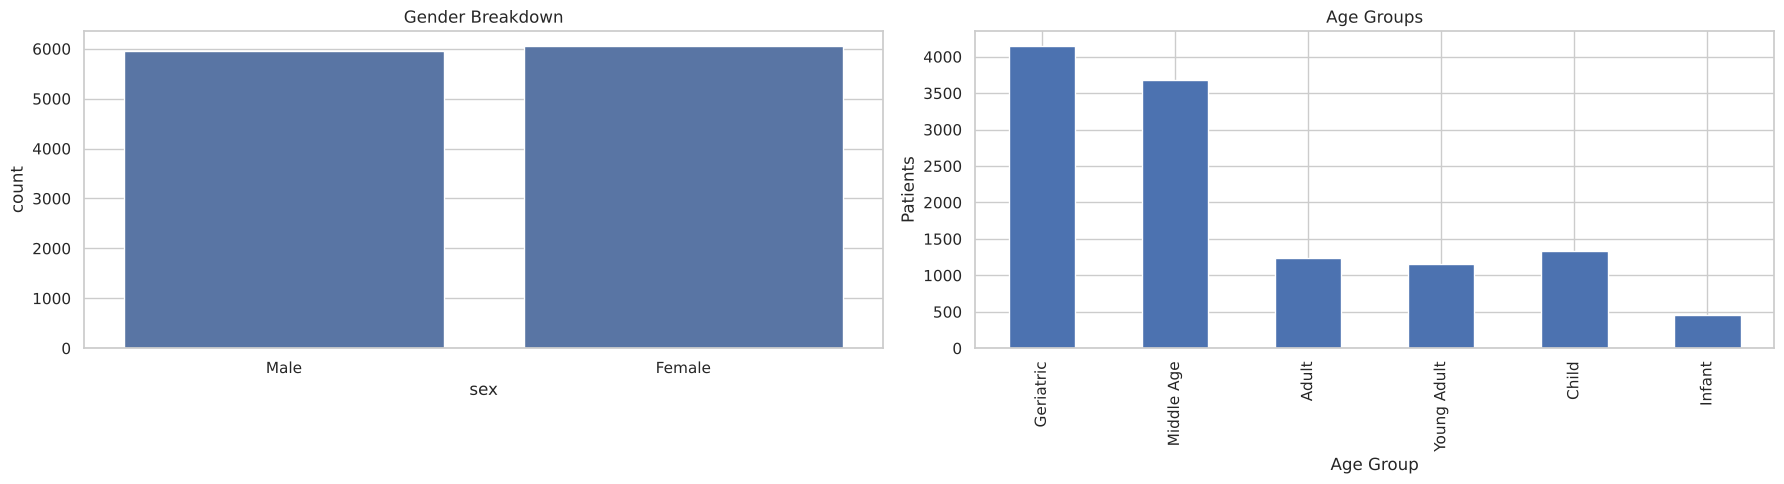

Total unique patients: 12,000, postcodes: 1,000
Male: 49.6%, age 2-98 years (median 50)
Age Group
Geriatric      4145
Middle Age     3682
Child          1335
Adult          1235
Young Adult    1150
Infant          453
Admissions aged 65+: 35.8%, male: 49.1%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Plot 1: sex
sns.countplot(data=patients, x="sex", ax=axes[0])
axes[0].set_title("Gender Breakdown")

# Plot 2: age groups
bins = [0, 5, 16, 25, 35, 65, 98]
labels = ["Infant", "Child", "Young Adult", "Adult", "Middle Age", "Geriatric"]
patients["Age Group"] = pd.cut(patients["age"], bins=bins, labels=labels, include_lowest=True)
# bars from oldest to youngest age group
age_order = ["Geriatric", "Middle Age", "Adult", "Young Adult", "Child", "Infant"]
patients["Age Group"].value_counts().reindex(age_order).plot.bar(ax=axes[1])
axes[1].set_title("Age Groups")
axes[1].set_ylabel("Patients")
plt.tight_layout()
plt.show()

print(f"Total unique patients: {patients.patient_id.nunique():,}, postcodes: {patients.postcode.nunique():,}")
print(f"Male: {(patients.sex == 'Male').mean():.1%}, age {patients.age.min()}-{patients.age.max()} years (median {patients.age.median():.0f})")
print(patients["Age Group"].value_counts().to_string())

# Shares of admissions (not patients) aged 65+ and male, used in Stage 3 of the ABM
adm_pat = admissions.merge(patients, on="patient_id")
print(f"Admissions aged 65+: {(adm_pat.age >= 65).mean():.1%}, male: {(adm_pat.sex == 'Male').mean():.1%}")

ADMISSION ANALYSIS

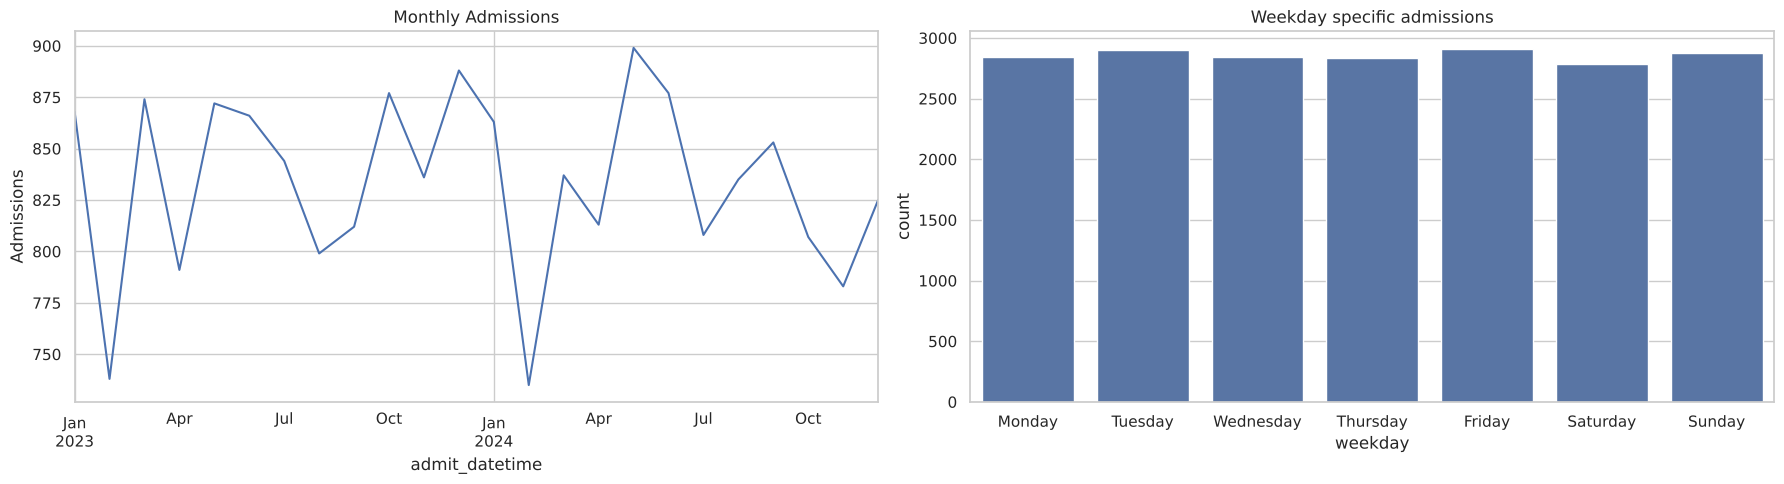

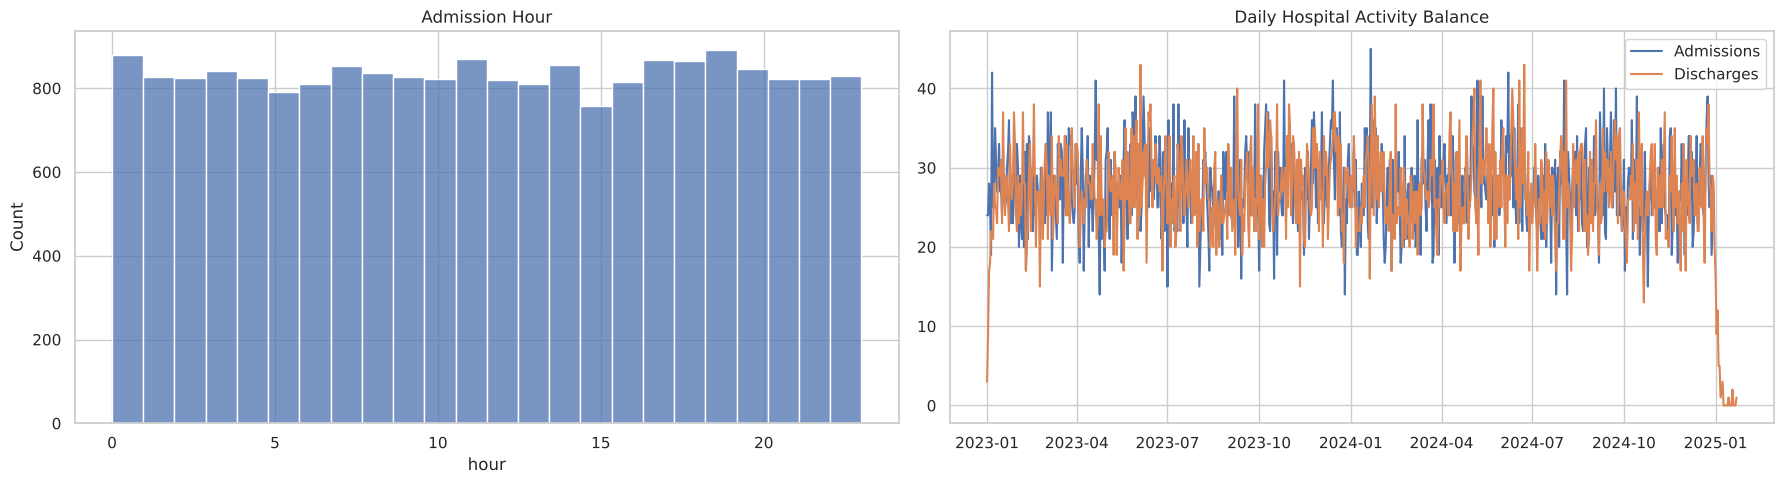

Admissions: 20,000, per month 735-899
Per weekday 2,789-2,912 (chi-square p = 0.70)
Mean admissions per hour of day: 1.04-1.22
Admissions from 01 Jan 2023 to 30 Dec 2024


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Plot 1: admissions per month
monthly = (admissions.set_index("admit_datetime").resample("ME").size())
monthly.plot(ax=axes[0])
axes[0].set_title("Monthly Admissions")
axes[0].set_ylabel("Admissions")

# Plot 2: admissions per weekday
admissions["weekday"] = admissions["admit_datetime"].dt.day_name()
order=[
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]
sns.countplot(data=admissions, x="weekday",order=order, ax=axes[1])
axes[1].set_title("Weekday specific admissions")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Plot 3: admissions by hour of day
admissions["hour"] = admissions["admit_datetime"].dt.hour
sns.histplot(admissions["hour"],bins=24, ax=axes[0])
axes[0].set_title("Admission Hour")

# Plot 4: daily admissions and discharges
daily_admissions = admissions.set_index("admit_datetime").resample("D").size()
daily_discharges = admissions.set_index("discharge_datetime").resample("D").size()
axes[1].plot(daily_admissions, label="Admissions")
axes[1].plot(daily_discharges, label="Discharges")
axes[1].legend()
axes[1].set_title("Daily Hospital Activity Balance")
plt.tight_layout()
plt.show()

weekday_counts = admissions["weekday"].value_counts()
per_hour = admissions["hour"].value_counts() / admissions["admit_datetime"].dt.floor("D").nunique()
print(f"Admissions: {admissions.admission_id.nunique():,}, per month {monthly.min()}-{monthly.max()}")
print(f"Per weekday {weekday_counts.min():,}-{weekday_counts.max():,} (chi-square p = {stats.chisquare(weekday_counts).pvalue:.2f})")
print(f"Mean admissions per hour of day: {per_hour.min():.2f}-{per_hour.max():.2f}")
print(f"Admissions from {admissions.admit_datetime.min():%d %b %Y} to {admissions.admit_datetime.max():%d %b %Y}")

LENGTH OF STAY ANALYSIS 

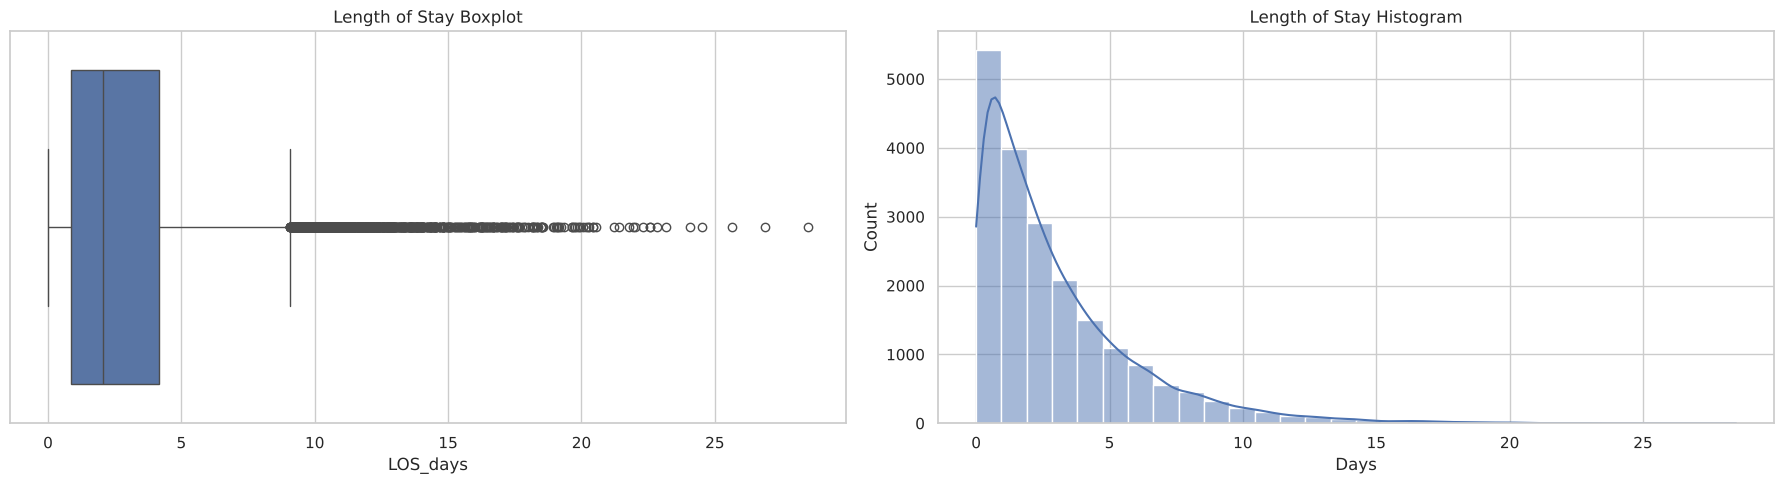

count    20000.000000
mean         2.994046
std          2.994060
min          0.000035
25%          0.862593
50%          2.073039
75%          4.148593
max         28.487149
Name: LOS_days, dtype: float64

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.boxplot(x=admissions["LOS_days"], ax=axes[0])
axes[0].set_title("Length of Stay Boxplot")

sns.histplot(admissions["LOS_days"], bins=30, kde=True, ax=axes[1])
axes[1].set_xlabel("Days")
axes[1].set_title("Length of Stay Histogram")
plt.tight_layout()
plt.show()

admissions["LOS_days"].describe()

ICD10 DIAGNOSIS ANALYSIS

In [9]:
# Descriptions written by the author (AI assisted and verified) as plain-language summaries to aid
# understanding; not official clinical definitions. Codes follow ICD-10-AM (AIHW).
# The 3 categories are an author-defined grouping, used for description only.
icd10_clinical_dictionary = {
    "E11": {
        "Diagnosis Name": "Type 2 Diabetes Mellitus",
        "Medical Description": "A chronic metabolic disorder characterized by systemic insulin resistance and relative pancreatic beta-cell dysfunction, resulting in persistent hyperglycemia.",
        "Lay Description": "A long-term health condition where the body struggles to process blood sugar properly.",
        "Consolidated Category": "1. Chronic Conditions (Metabolic, Cardiovascular & Cancer)"
    },
    "I21": {
        "Diagnosis Name": "Acute Myocardial Infarction",
        "Medical Description": "Myocardial tissue necrosis resulting from a sudden, acute obstruction of a coronary artery causing prolonged cardiac ischemia.",
        "Lay Description": "A heart attack, which happens when blood flow to part of the heart muscle is suddenly blocked.",
        "Consolidated Category": "1. Chronic Conditions (Metabolic, Cardiovascular & Cancer)"
    },
    "A41": {
        "Diagnosis Name": "Sepsis",
        "Medical Description": "A life-threatening organ dysfunction syndrome caused by a dysregulated, systemic host response to a documented or suspected bacterial infection.",
        "Lay Description": "A life-threatening medical emergency caused by the body's extreme, overwhelming response to an infection.",
        "Consolidated Category": "2. Systemic Infectious & Respiratory Illnesses"
    },
    "J18": {
        "Diagnosis Name": "Pneumonia (Unspecified Organism)",
        "Medical Description": "Acute exudative inflammation of the lung parenchyma characterized by alveolar consolidation and impaired gas exchange.",
        "Lay Description": "A severe infection of the lungs that fills the air sacs with fluid, making it difficult to breathe.",
        "Consolidated Category": "2. Systemic Infectious & Respiratory Illnesses"
    },
    "C34": {
        "Diagnosis Name": "Malignant Neoplasm of Bronchus and Lung",
        "Medical Description": "A primary oncological disease characterized by uncontrolled, autonomous cellular proliferation within pulmonary bronchial tissue.",
        "Lay Description": "Lung cancer, a serious disease where harmful tumors grow inside the airways or lung tissues.",
        "Consolidated Category": "1. Chronic Conditions (Metabolic, Cardiovascular & Cancer)"
    },
    "N39": {
        "Diagnosis Name": "Other Disorders of Urinary System",
        "Medical Description": "A broad category of urinary system disorders, including urinary tract infection where the site is not specified.",
        "Lay Description": "Various bladder or urinary system problems, which frequently lead to urinary tract infections.",
        "Consolidated Category": "3. Genitourinary & Acute Surgical Emergencies"
    },
    "K35": {
        "Diagnosis Name": "Acute Appendicitis",
        "Medical Description": "Rapidly progressive bacterial infection and inflammation of the vermiform appendix, requiring urgent surgical excision to prevent perforation.",
        "Lay Description": "Sudden, painful swelling of the appendix that requires emergency surgery to remove it before it bursts.",
        "Consolidated Category": "3. Genitourinary & Acute Surgical Emergencies"
    }
}

# Map descriptions and categories onto the admissions
admissions["Diagnosis_Name"] = admissions["icd10_principal"].map(lambda x: icd10_clinical_dictionary.get(x, {}).get("Diagnosis Name"))
admissions["Medical_Description"] = admissions["icd10_principal"].map(lambda x: icd10_clinical_dictionary.get(x, {}).get("Medical Description"))
admissions["Lay_Description"] = admissions["icd10_principal"].map(lambda x: icd10_clinical_dictionary.get(x, {}).get("Lay Description"))
admissions["Consolidated_Category"] = admissions["icd10_principal"].map(lambda x: icd10_clinical_dictionary.get(x, {}).get("Consolidated Category"))

# Device exposure and infection flags per admission
device_admissions = set(device["admission_id"].unique())
admissions["Device_Exposed"] = admissions["admission_id"].isin(device_admissions)

infected_admissions = set(infection["admission_id"].unique())
admissions["Developed_Infection"] = admissions["admission_id"].isin(infected_admissions)

# Device exposure and infection (%) for each diagnosis code
icd_analysis = admissions.groupby("icd10_principal").agg(
    Admissions_Count=("admission_id", "count"),
    Device_Exposure_Rate=("Device_Exposed", lambda x: round(x.mean() * 100, 2)),
    Infection_Rate=("Developed_Infection", lambda x: round(x.mean() * 100, 2))
).reset_index()

icd_analysis["Medical_Terms"] = icd_analysis["icd10_principal"].map(lambda x: icd10_clinical_dictionary[x]["Medical Description"])
icd_analysis["Lay_Terms"] = icd_analysis["icd10_principal"].map(lambda x: icd10_clinical_dictionary[x]["Lay Description"])

print("--- ICD-10 SPECIFIC CODE ANALYSIS ---")
display(icd_analysis)

# The same for the 3 categories
category_summary = admissions.groupby("Consolidated_Category").agg(
    Total_Admissions=("admission_id", "count"),
    Overall_Device_Exposure_Rate=("Device_Exposed", lambda x: f"{x.mean()*100:.2f}%"),
    Overall_Infection_Rate=("Developed_Infection", lambda x: f"{x.mean()*100:.2f}%")
).reset_index()
pd.set_option("display.max_colwidth", None)
print("\n--- CONSOLIDATED 3-CATEGORY ANALYSIS ---")
display(category_summary)

--- ICD-10 SPECIFIC CODE ANALYSIS ---


,icd10_principal,Admissions_Count,Device_Exposure_Rate,Infection_Rate,Medical_Terms,Lay_Terms
0,A41,2863,43.59,9.99,A life-threatening organ dysfunction syndrome ...,A life-threatening medical emergency caused by...
1,C34,2768,45.05,10.22,A primary oncological disease characterized by...,"Lung cancer, a serious disease where harmful t..."
2,E11,2973,43.63,10.63,A chronic metabolic disorder characterized by ...,A long-term health condition where the body st...
3,I21,2826,44.34,9.41,Myocardial tissue necrosis resulting from a su...,"A heart attack, which happens when blood flow ..."
4,J18,2848,43.08,9.38,Acute exudative inflammation of the lung paren...,A severe infection of the lungs that fills the...
5,K35,2840,43.98,10.07,Rapidly progressive bacterial infection and in...,"Sudden, painful swelling of the appendix that ..."
6,N39,2882,44.59,10.27,"A broad category of urinary system disorders, ...","Various bladder or urinary system problems, wh..."



--- CONSOLIDATED 3-CATEGORY ANALYSIS ---


,Consolidated_Category,Total_Admissions,Overall_Device_Exposure_Rate,Overall_Infection_Rate
0,"1. Chronic Conditions (Metabolic, Cardiovascular & Cancer)",8567,44.32%,10.10%
1,2. Systemic Infectious & Respiratory Illnesses,5711,43.34%,9.68%
2,3. Genitourinary & Acute Surgical Emergencies,5722,44.29%,10.17%


WARD MOVEMENT ANALYSIS

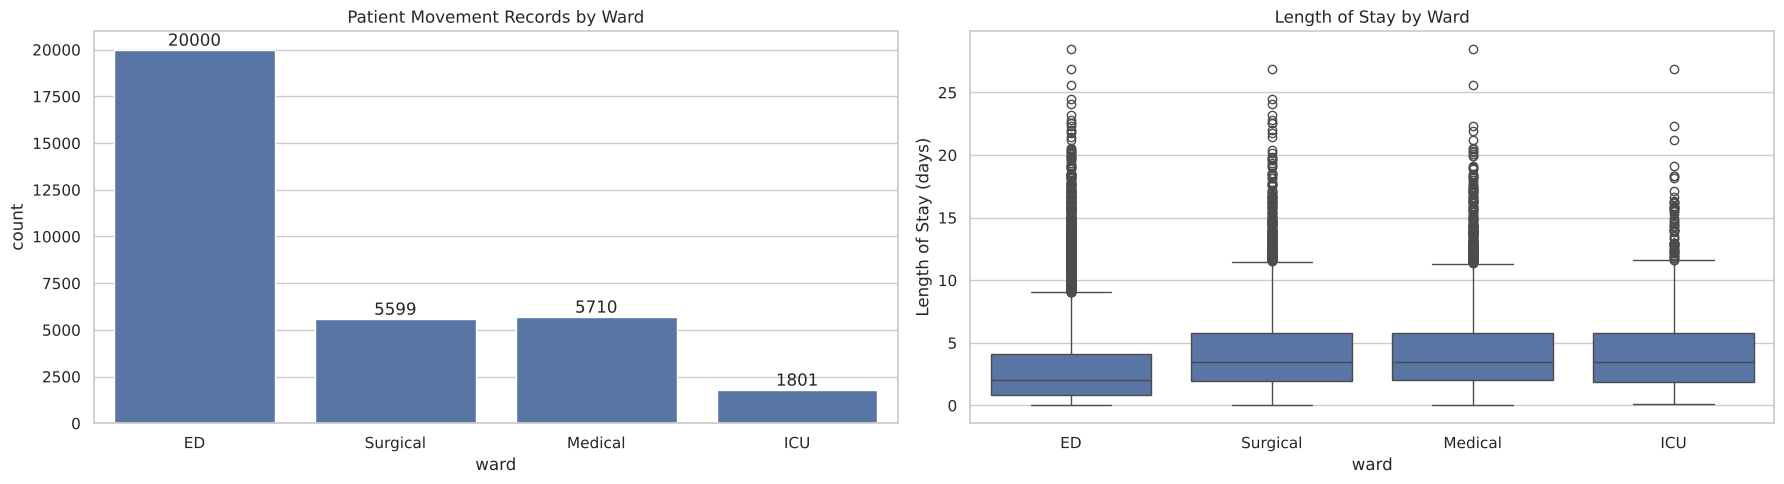

Median hours per ward stay: {'ED': 20.0, 'ICU': 19.1, 'Medical': 19.8, 'Surgical': 19.5}
Admissions with 1, 2 or 3 ward stays (%): {1: 39.9, 2: 54.6, 3: 5.5}
next_ward  Discharge  ICU  Medical  Surgical
ward                                        
ED              39.9  9.0     25.8      25.2
ICU             39.1  0.0     30.0      30.9
Medical        100.0  0.0      0.0       0.0
Surgical       100.0  0.0      0.0       0.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Plot 1: ward stay records per ward
sns.countplot(data=ward, x="ward", ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container)
axes[0].set_title("Patient Movement Records by Ward")

# Plot 2: length of stay of the admission, by ward visited
ward_los = ward.merge(admissions[["admission_id", "LOS_days"]], on="admission_id", how="left")
sns.boxplot(data=ward_los, x="ward", y="LOS_days", ax=axes[1])
axes[1].set_title("Length of Stay by Ward")
axes[1].set_ylabel("Length of Stay (days)")
plt.tight_layout()
plt.show()

# Hours per ward stay, ward stays per admission and where patients go next
ward["hours"] = (ward["end_datetime"] - ward["start_datetime"]).dt.total_seconds() / 3600
print("Median hours per ward stay:", ward.groupby("ward")["hours"].median().round(1).to_dict())
print("Admissions with 1, 2 or 3 ward stays (%):",
      (100 * ward.groupby("admission_id").size().value_counts(normalize=True).sort_index()).round(1).to_dict())
ws = ward.sort_values(["admission_id", "start_datetime"]).copy()
ws["next_ward"] = ws.groupby("admission_id")["ward"].shift(-1).fillna("Discharge")
print((100 * pd.crosstab(ws["ward"], ws["next_ward"], normalize="index")).round(1))

MEDICATION ANALYSIS

Admissions that received an antibiotic: 2,000


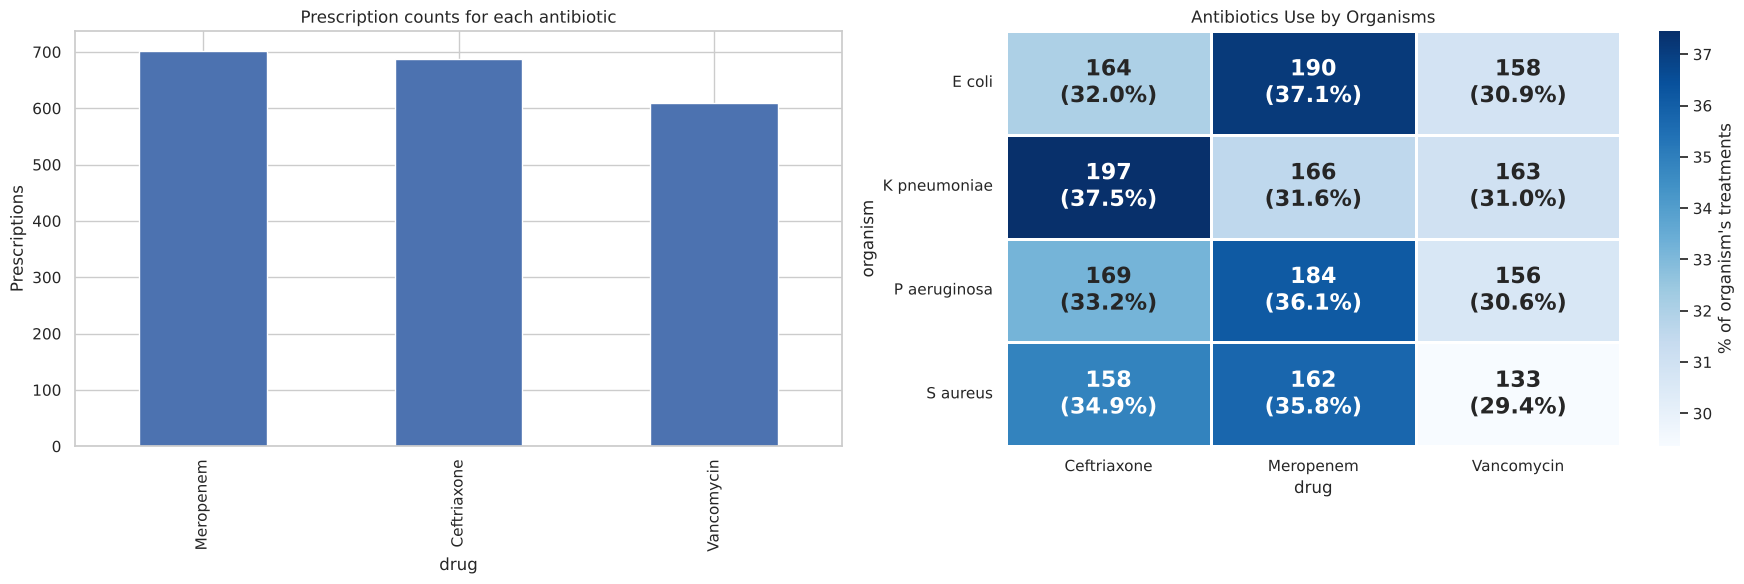

In [11]:
print(f"Admissions that received an antibiotic: {medications.admission_id.nunique():,}")

# Plot 1: prescriptions per antibiotic
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
drug = medications["drug"].value_counts()
drug.plot.bar(ax=axes[0])
axes[0].set_ylabel("Prescriptions")
axes[0].set_title("Prescription counts for each antibiotic")

# Plot 2: antibiotic received for each organism (count and % of that organism's infections)
drug_org = infection.merge(medications,on="admission_id",how="inner")
heatmap_data = pd.crosstab(drug_org["organism"], drug_org["drug"])
heatmap_percentages = heatmap_data.div(heatmap_data.sum(axis=1), axis=0) * 100
annot_labels = np.array([
    f"{count:,}\n({pct:.1f}%)" 
    for count, pct in zip(heatmap_data.values.flatten(), heatmap_percentages.values.flatten())
]).reshape(heatmap_data.shape)
sns.heatmap(
    heatmap_percentages,
    annot=annot_labels,
    fmt="",
    cmap="Blues",
    cbar_kws={'label': "% of organism's treatments"},
    linewidths=1,
    linecolor="white",
    annot_kws={"fontsize": 16, "fontweight": "bold"},
    ax=axes[1]
)
axes[1].set_title("Antibiotics Use by Organisms")
axes[1].tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

INFECTION ANALYSIS

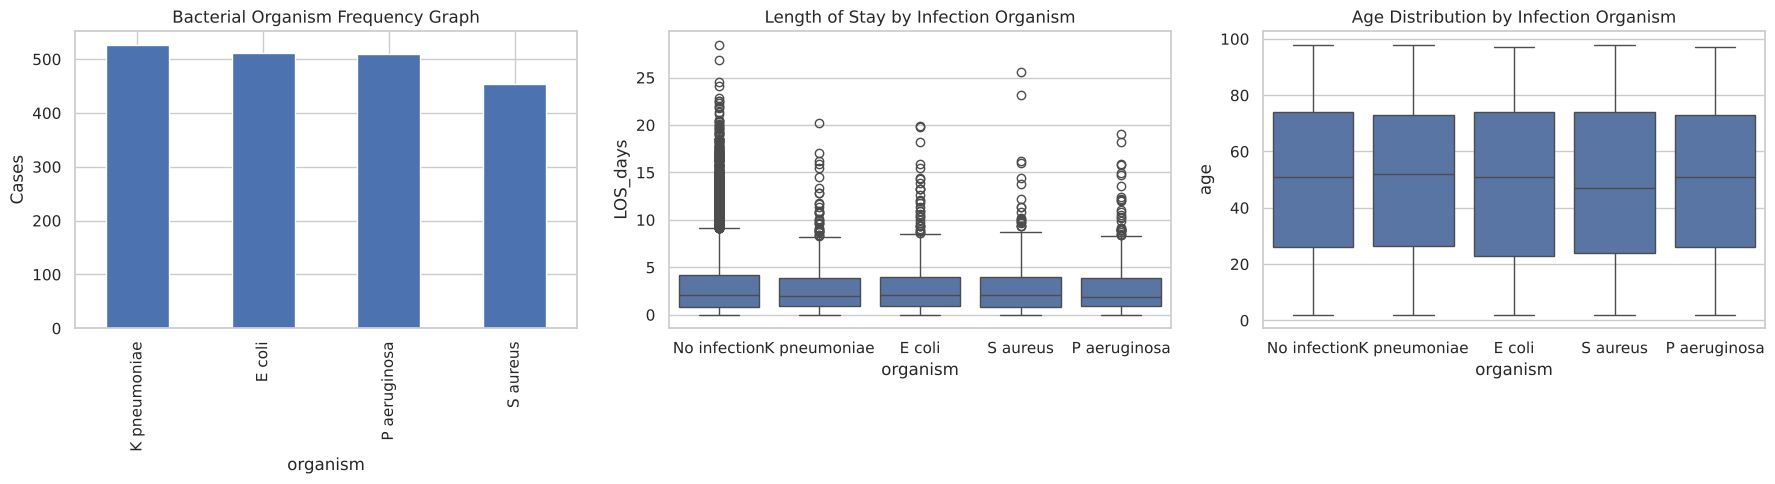

Infected admissions: 2,000 (1,857 patients)


,Full Scientific Name,Gram Stain & Morphology,Medical Description,Lay Description,Primary Device Association
K pneumoniae,Klebsiella pneumoniae,"Gram-negative, encapsulated, rod-shaped bacterium","An opportunistic pathogen that colonizes human mucosal surfaces. It is a major cause of severe hospital-acquired pneumonia, bloodstream infections, and urinary tract infections, often exhibiting resistance to multiple antibiotic classes.","A common hospital germ that can infect the lungs, blood, or bladder, and is notorious for being hard to treat with standard antibiotics.","Ventilators, Central Venous Catheters, and Urinary Catheters"
E coli,Escherichia coli,"Gram-negative, rod-shaped bacterium","A facultative anaerobic bacterium commonly residing in the lower intestine of warm-blooded organisms. In healthcare settings, pathogenic strains are the leading cause of catheter-associated urinary tract infections (CAUTIs) and secondary bacteremia.",A bacteria normally found in the gut that can cause severe urinary tract or blood infections when introduced to sterile areas of the body via medical gear.,Urinary Catheters
P aeruginosa,Pseudomonas aeruginosa,"Gram-negative, flagellated, rod-shaped bacterium","An highly resilient environmental bacterium that thrives in moist hospital environments (sinks, respiratory equipment). It causes severe opportunistic infections in immunocompromised or critically ill patients and is highly resistant to chemical disinfectants and antibiotics.","A tough environmental germ that thrives in damp areas and easily infects critically ill patients, especially those on breathing machines or catheters.",Mechanical Ventilators and Urinary Catheters
S aureus,Staphylococcus aureus,"Gram-positive, coccus-shaped (spherical) bacterium in clusters","A major human pathogen that colonizes the skin and nares. It easily invades the bloodstream through broken skin or invasive device insertion sites, leading to severe device-associated bacteremia, endocarditis, and surgical site infections.",A common skin bacteria that becomes highly dangerous and causes serious blood or wound infections if it enters the body through surgical cuts or medical tubes.,Central Venous Lines and Surgical Drainages


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# Plot 1: infections by organism
infection["organism"].value_counts().plot.bar(ax=axes[0])
axes[0].set_ylabel("Cases")
axes[0].set_title("Bacterial Organism Frequency Graph")

# Plot 2: length of stay by organism
los_infection = admissions.merge(infection, on="admission_id", how="left")
los_infection["organism"] = (los_infection["organism"].fillna("No infection"))
sns.boxplot(data=los_infection,x="organism",y="LOS_days", ax=axes[1])
axes[1].set_title("Length of Stay by Infection Organism")

# Plot 3: age by organism
age_inf = admissions.merge(patients,on="patient_id").merge(infection,on="admission_id",how="left")
age_inf["organism"] = (age_inf["organism"].fillna("No infection"))
sns.boxplot(data=age_inf,x="organism",y="age",ax=axes[2])
axes[2].set_title("Age Distribution by Infection Organism")
plt.tight_layout()
plt.show()

infected_patients = admissions.loc[admissions.admission_id.isin(infection.admission_id), "patient_id"].nunique()
print(f"Infected admissions: {infection.admission_id.nunique():,} ({infected_patients:,} patients)")

# Organism descriptions written by the author (AI assisted and verified) to aid understanding
organism_dictionary = {
    "K pneumoniae": {
        "Full Scientific Name": "Klebsiella pneumoniae",
        "Gram Stain & Morphology": "Gram-negative, encapsulated, rod-shaped bacterium",
        "Medical Description": "An opportunistic pathogen that colonizes human mucosal surfaces. It is a major cause of severe hospital-acquired pneumonia, bloodstream infections, and urinary tract infections, often exhibiting resistance to multiple antibiotic classes.",
        "Lay Description": "A common hospital germ that can infect the lungs, blood, or bladder, and is notorious for being hard to treat with standard antibiotics.",
        "Primary Device Association": "Ventilators, Central Venous Catheters, and Urinary Catheters"
    },
    "E coli": {
        "Full Scientific Name": "Escherichia coli",
        "Gram Stain & Morphology": "Gram-negative, rod-shaped bacterium",
        "Medical Description": "A facultative anaerobic bacterium commonly residing in the lower intestine of warm-blooded organisms. In healthcare settings, pathogenic strains are the leading cause of catheter-associated urinary tract infections (CAUTIs) and secondary bacteremia.",
        "Lay Description": "A bacteria normally found in the gut that can cause severe urinary tract or blood infections when introduced to sterile areas of the body via medical gear.",
        "Primary Device Association": "Urinary Catheters"
    },
    "P aeruginosa": {
        "Full Scientific Name": "Pseudomonas aeruginosa",
        "Gram Stain & Morphology": "Gram-negative, flagellated, rod-shaped bacterium",
        "Medical Description": "An highly resilient environmental bacterium that thrives in moist hospital environments (sinks, respiratory equipment). It causes severe opportunistic infections in immunocompromised or critically ill patients and is highly resistant to chemical disinfectants and antibiotics.",
        "Lay Description": "A tough environmental germ that thrives in damp areas and easily infects critically ill patients, especially those on breathing machines or catheters.",
        "Primary Device Association": "Mechanical Ventilators and Urinary Catheters"
    },
    "S aureus": {
        "Full Scientific Name": "Staphylococcus aureus",
        "Gram Stain & Morphology": "Gram-positive, coccus-shaped (spherical) bacterium in clusters",
        "Medical Description": "A major human pathogen that colonizes the skin and nares. It easily invades the bloodstream through broken skin or invasive device insertion sites, leading to severe device-associated bacteremia, endocarditis, and surgical site infections.",
        "Lay Description": "A common skin bacteria that becomes highly dangerous and causes serious blood or wound infections if it enters the body through surgical cuts or medical tubes.",
        "Primary Device Association": "Central Venous Lines and Surgical Drainages"
    }
}
organism_df = pd.DataFrame(organism_dictionary).T
pd.set_option("display.max_colwidth", None)
display(organism_df)

DEVICE EXPOSURE

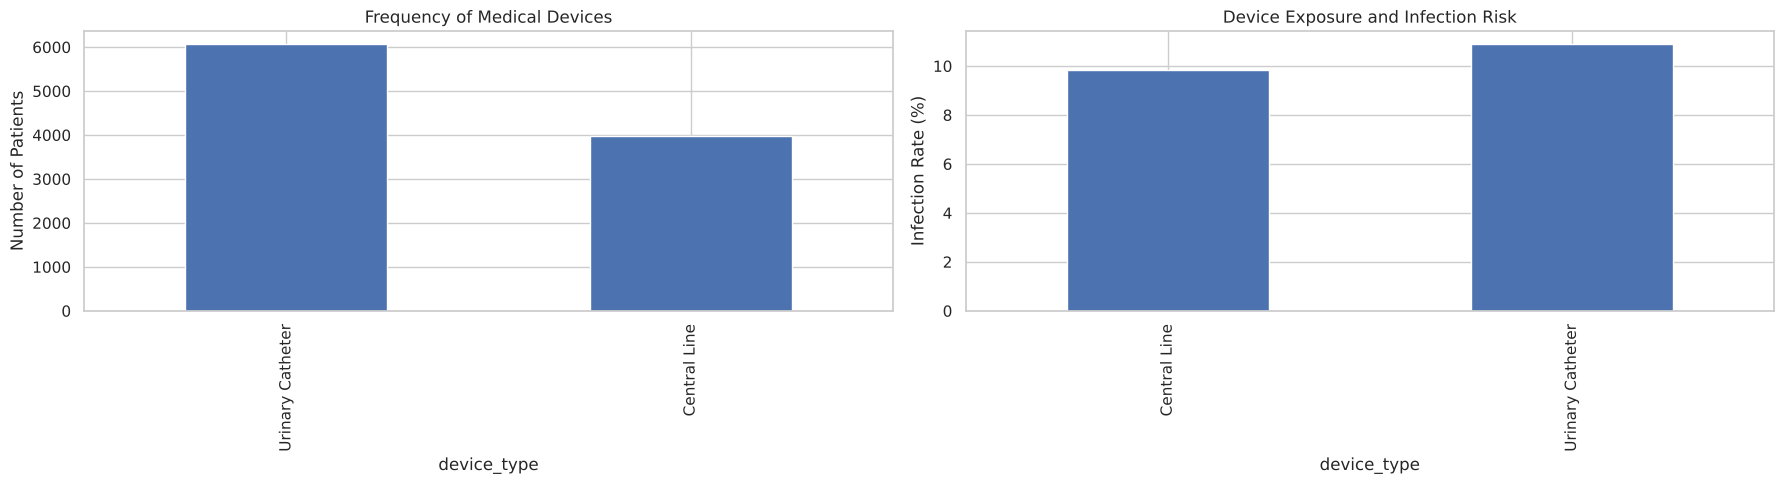

Admissions with at least one device: 8,806 (44.0%)
Infected admissions (%) without and with a device: {False: 9.7, True: 10.4}


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Plot 1: device episodes by type
device["device_type"].value_counts().plot.bar(ax=axes[0])
axes[0].set_title("Frequency of Medical Devices")
axes[0].set_ylabel("Number of Patients")

# Plot 2: % of device episodes whose admission had an infection, by device type
device_analysis = device.merge(infection[["admission_id", "organism"]], on="admission_id", how="left")
device_analysis["infection"] = device_analysis["organism"].notna()
device_rate = device_analysis.groupby("device_type")["infection"].mean() * 100
device_rate.plot(kind="bar", ax=axes[1])
axes[1].set_ylabel("Infection Rate (%)")
axes[1].set_title("Device Exposure and Infection Risk")
plt.tight_layout()
plt.show()

print(f"Admissions with at least one device: {device.admission_id.nunique():,} ({device.admission_id.nunique() / len(admissions):.1%})")
print("Infected admissions (%) without and with a device:",
      (100 * admissions.groupby("Device_Exposed")["Developed_Infection"].mean()).round(1).to_dict())

READMISSION ANALYSIS

Patients with at least one admission: 9,746, admitted more than once: 5,930


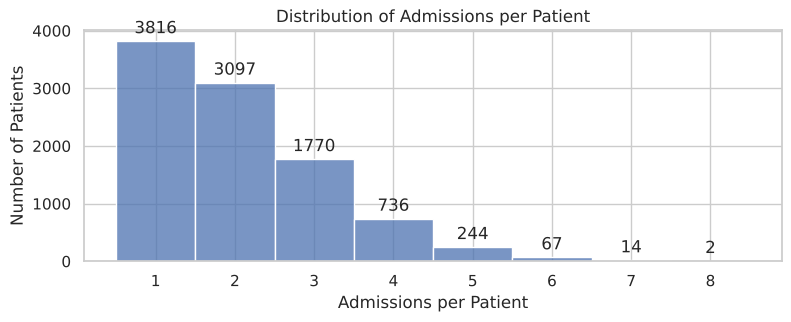

In [14]:
# Number of admissions per patient
readmissions = admissions.groupby("patient_id").size()
print(f"Patients with at least one admission: {len(readmissions):,}, admitted more than once: {(readmissions > 1).sum():,}")
ax = sns.histplot(readmissions, bins=8, discrete=True)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
plt.xlabel("Admissions per Patient")
plt.ylabel("Number of Patients")
plt.title("Distribution of Admissions per Patient")
plt.show()

SANKEY PLOT

In [15]:
# Patient flow: each admission's ward sequence (repeats collapsed), from the community to discharge
NODES = ["Community", "ED", "Medical", "Surgical", "ICU", "Discharged"]
NODE_LABELS = ["Community<br>(Admission)", "Emergency Department (ED)", "Medical Ward", "Surgical Ward",
               "Intensive Care Unit (ICU)", "Discharged"]
NODE_COLORS = ["rgba(108, 117, 125, 0.85)", "rgba(54, 162, 235, 0.85)", "rgba(255, 159, 64, 0.85)",
               "rgba(75, 192, 192, 0.85)", "rgba(255, 99, 132, 0.85)", "rgba(40, 167, 69, 0.85)"]
LINK_COLORS = ["rgba(108, 117, 125, 0.25)", "rgba(54, 162, 235, 0.25)", "rgba(255, 159, 64, 0.25)",
               "rgba(75, 192, 192, 0.25)", "rgba(255, 99, 132, 0.25)"]

# Count every step of every pathway
transitions = {}
for _, stays in ward.sort_values(["admission_id", "start_datetime"]).groupby("admission_id")["ward"]:
    path = ["Community"]
    for w in stays:
        if w != path[-1]:
            path.append(w)
    path.append("Discharged")
    for src, tgt in zip(path[:-1], path[1:]):
        transitions[(src, tgt)] = transitions.get((src, tgt), 0) + 1

# Node labels: number entering each ward and where those patients went next
labels = []
for node, title in zip(NODES, NODE_LABELS):
    entered = sum(n for (s, t), n in transitions.items() if t == node)
    out = sorted([(t, n) for (s, t), n in transitions.items() if s == node], key=lambda x: -x[1])
    if node == "Community":
        labels.append(f"<b>{title}</b><br>N admission encounters = {sum(n for _, n in out):,}")
    elif node == "Discharged":
        labels.append(f"<b>{title}</b><br>N = {entered:,}")
    else:
        # destination counts with the observed transfer probability (share of patients leaving this ward)
        total_out = sum(n for _, n in out)
        labels.append(f"<b>{title}</b><br>N entered = {entered:,}<br><br><b>Destination (probability):</b><br>"
                      + "<br>".join(f"{t}: {n:,} ({n / total_out:.1%})" for t, n in out))

sources = [NODES.index(s) for s, t in transitions]
targets = [NODES.index(t) for s, t in transitions]
fig = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(pad=25, thickness=30, label=labels, color=NODE_COLORS, line=dict(color="rgba(0,0,0,0.4)", width=0.5)),
    link=dict(source=sources, target=targets, value=list(transitions.values()),
              color=[LINK_COLORS[s] for s in sources],
              hovertemplate="<b>%{source.label}</b> → <b>%{target.label}</b><br>Admission encounters: %{value:,}<extra></extra>")))
fig.update_layout(font=dict(size=17, family="DejaVu Sans"), width=1400, height=800,
                  margin=dict(l=10, r=10, t=10, b=10), plot_bgcolor="white")
fig.show()